# 09 — Testing the beam widths (FWHM) and the smoothing

The project leans on two numbers: the TRIS beam's half-power widths, **19.155° (E plane)**
and **23.366° (H plane)**. The larger one is stage 2's smoothing target
(`beam_matching.target_fwhm_deg`). This notebook checks that the code producing and using
them is right, before anything else is tested.

| function | where | what it does |
|---|---|---|
| `TRISPrincipalPlaneCuts.half_power_full_width_deg()` | `limTOD/tris/archive.py` | FWHM of the E and H cuts, where each crosses −3.0103 dB |
| `approximate_tris_gaussian_beam_map()` | `limTOD/tris/beam.py` | elliptical Gaussian beam from (FWHM_E, FWHM_H) |
| `tris_cut_beam_response()` / `tris_cut_beam_map()` | `limTOD/tris/beam.py` | the archive-cut beam: E and H cuts blended with cos²φ / sin²φ |
| `extra_fwhm_deg()` / `smooth_to_target()` | `moonrunes/stage2_beam_matching.py` | the quadrature kernel and the smoothing |

**What is checked**

1. The σ ↔ FWHM constant: FWHM = 2√(2 ln 2) σ = 2.35482 σ.
2. An elliptical Gaussian built from σ_E, σ_H gives back 19.155° and 23.366° from the FWHM function.
3. Degree/radian slips and σ-vs-FWHM mix-ups, the usual culprits: what each would produce,
   and a check that none is happening.
4. The archive-cut beam: its FWHM measured numerically from the E and H cuts.
5. The cut beam at φ = 0 is the E cut and at φ = 90° is the H cut.
6. **Test 2, a round trip:** build an elliptical Gaussian beam *map* with FWHM 19.155° /
   23.366°, read its E and H cuts back off the map, run them through the FWHM function,
   and require the two numbers back to 0.1%. This is repeated at every nside from 16 to
   1024, because the pipeline builds its beam at nside 16.

Every check ends in an `assert`, so the notebook fails loudly if anything breaks. The same
checks run under pytest in `tests/test_beam_fwhm.py`.

In [ ]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": "white"})

from moonrunes.config import load_config
from moonrunes.stage1_tris_maps import import_limtod_tris
from moonrunes.stage2_beam_matching import extra_fwhm_deg, smooth_to_target

config = load_config(REPO / "configs" / "run_config.yaml")
tris = import_limtod_tris(config)
CUTS = tris.read_tris_beam_cuts(config.resolve_path("paths.tris_archive_dir") / "TRIS_Beam_Profile.txt")

FWHM_E, FWHM_H = 19.155, 23.366          # the expected values (degrees)
HALF_DB = -10 * np.log10(2)              # half power in dB: -3.0103
RESULTS = []                             # (check, value, expected, pass) for the summary

def record(check, value, expected, ok):
    RESULTS.append((check, value, expected, bool(ok)))
    print(f"{'PASS' if ok else 'FAIL'}  {check}: {value}  (expected {expected})")
    assert ok, check

def fwhm_from_profile(theta_deg, response):
    # FWHM of a peak-normalised profile sampled from the centre outwards: twice the angle
    # where it first falls to half, by linear interpolation between the two bracketing samples.
    r = np.asarray(response) / response[0]
    i = int(np.argmax(r < 0.5))
    t0, t1, r0, r1 = theta_deg[i - 1], theta_deg[i], r[i - 1], r[i]
    return 2 * (t0 + (0.5 - r0) / (r1 - r0) * (t1 - t0))

print(f"archive cuts: {CUTS.angle_deg.size} angles, {CUTS.angle_deg.min():.0f}–{CUTS.angle_deg.max():.0f}°, "
      f"spacing {np.unique(np.diff(CUTS.angle_deg))}°")

archive cuts: 55 angles, 0–176°, spacing [1. 2. 5.]°


---
## 1. The σ ↔ FWHM constant

For a Gaussian $\exp(-\theta^2/2\sigma^2)$, half power is reached at
$\theta = \sigma\sqrt{2\ln 2}$, so

$$\mathrm{FWHM} = 2\sqrt{2\ln 2}\,\sigma \approx 2.35482\,\sigma.$$

limTOD writes the factor as `2.0 * np.sqrt(2.0 * np.log(2.0))`. Below: the constant, and
the σ of each TRIS plane.

In [ ]:
K = 2 * np.sqrt(2 * np.log(2))
print(f"2*sqrt(2 ln 2) = {K:.6f}")
record("FWHM/sigma constant", round(K, 6), 2.354820, abs(K - 2.3548200450309493) < 1e-12)
# The rounded 2.3548 costs ~1e-5 relative -- 0.0002 deg on 23 deg, irrelevant.
print(f"rounded 2.3548 vs exact: relative difference {abs(2.3548 / K - 1):.1e}")

SIGMA_E, SIGMA_H = FWHM_E / K, FWHM_H / K
print(f"sigma_E = {SIGMA_E:.4f} deg, sigma_H = {SIGMA_H:.4f} deg")
# Half power must fall exactly at FWHM/2:
for name, s, f in (("E", SIGMA_E, FWHM_E), ("H", SIGMA_H, FWHM_H)):
    v = np.exp(-0.5 * (f / 2 / s) ** 2)
    record(f"Gaussian({name}) at FWHM/2", round(v, 12), 0.5, abs(v - 0.5) < 1e-12)

2*sqrt(2 ln 2) = 2.354820
PASS  FWHM/sigma constant: 2.35482  (expected 2.35482)
rounded 2.3548 vs exact: relative difference 8.5e-06
sigma_E = 8.1344 deg, sigma_H = 9.9226 deg
PASS  Gaussian(E) at FWHM/2: 0.5  (expected 0.5)
PASS  Gaussian(H) at FWHM/2: 0.5  (expected 0.5)


---
## 2. An elliptical Gaussian through the FWHM function

Build the E and H cuts of an elliptical Gaussian from σ_E and σ_H, in dB as the archive
stores them ($10\log_{10}$ of the power), wrap them in a `TRISPrincipalPlaneCuts`, and ask
`half_power_full_width_deg()` for the widths.

* **Fine grid (0.01°):** tests the function's arithmetic alone. It must return 19.155° and
  23.366° to interpolation error (about $10^{-6}$ degrees).
* **The archive's own grid** (2° steps around the half-power point): what the function
  sees with real data. It interpolates **linearly in dB** between samples, and a Gaussian
  is a parabola in dB, so the straight line between two samples lies *below* the curve and
  crosses −3 dB early. The width comes out **too narrow** by a predictable amount.
  The test therefore computes that chord crossing independently and requires the function
  to match it exactly. The size of the bias is reported as a finding.

In [ ]:
def gaussian_cuts(angles):
    db = lambda s: 10 * np.log10(np.exp(-0.5 * (angles / s) ** 2))
    return tris.TRISPrincipalPlaneCuts(angle_deg=angles, h_plane_db=db(SIGMA_H), e_plane_db=db(SIGMA_E))

def chord_fwhm(angles, sigma):
    # Independent calculation: where the straight line between the two samples that bracket
    # half power (in dB) crosses -3.0103 dB, times two.
    db = 10 * np.log10(np.exp(-0.5 * (angles / sigma) ** 2))
    i = int(np.argmax(db < HALF_DB))
    return 2 * (angles[i - 1] + (HALF_DB - db[i - 1]) / (db[i] - db[i - 1]) * (angles[i] - angles[i - 1]))

e, h = gaussian_cuts(np.arange(0, 60, 0.01)).half_power_full_width_deg()
print(f"fine 0.01° grid: E {e:.6f}, H {h:.6f}  (errors {e - FWHM_E:+.1e}, {h - FWHM_H:+.1e} deg)")
record("Gaussian E FWHM, fine grid", round(e, 5), FWHM_E, abs(e - FWHM_E) < 1e-5)
record("Gaussian H FWHM, fine grid", round(h, 5), FWHM_H, abs(h - FWHM_H) < 1e-5)

e, h = gaussian_cuts(CUTS.angle_deg).half_power_full_width_deg()
ce, ch = chord_fwhm(CUTS.angle_deg, SIGMA_E), chord_fwhm(CUTS.angle_deg, SIGMA_H)
print(f"\narchive grid: E {e:.5f}, H {h:.5f};  independent chord calculation: E {ce:.5f}, H {ch:.5f}")
record("Gaussian E FWHM, archive grid = chord crossing", round(e, 6), round(ce, 6), abs(e - ce) < 1e-9)
record("Gaussian H FWHM, archive grid = chord crossing", round(h, 6), round(ch, 6), abs(h - ch) < 1e-9)
BIAS_E, BIAS_H = e - FWHM_E, h - FWHM_H
print(f"FINDING: on the archive's 2° grid, linear-in-dB interpolation under-reads a Gaussian's FWHM "
      f"by {BIAS_E:+.3f}° (E) and {BIAS_H:+.3f}° (H)")

# The archive cuts themselves give the two numbers the project uses.
e, h = CUTS.half_power_full_width_deg()
print(f"\narchive cuts: E {e:.4f}°, H {h:.4f}°;  config target_fwhm_deg = "
      f"{config.require('beam_matching.target_fwhm_deg')}")
record("archive E FWHM", round(e, 3), FWHM_E, abs(e - FWHM_E) < 5e-4)
record("archive H FWHM", round(h, 3), FWHM_H, abs(h - FWHM_H) < 5e-4)
record("config target = archive H", config.require("beam_matching.target_fwhm_deg"), round(h, 3),
       abs(float(config.require("beam_matching.target_fwhm_deg")) - h) < 5e-4)

# How big is that bias on the REAL cuts? Replace the straight line by a parabola through the
# three samples nearest half power (in dB). Exact for a Gaussian; for the real beam, an estimate.
def parabola_fwhm(angles, db):
    i = int(np.argmax(db < HALF_DB))
    j = slice(i - 2, i + 1) if abs(db[i - 1] - HALF_DB) < abs(db[i] - HALF_DB) else slice(i - 1, i + 2)
    a, b, c = np.polyfit(angles[j], db[j], 2)
    roots = np.roots([a, b, c - HALF_DB]).real
    return 2 * roots[(roots > angles[j][0]) & (roots < angles[j][-1])][0]
pe = parabola_fwhm(CUTS.angle_deg, CUTS.e_plane_db)
ph = parabola_fwhm(CUTS.angle_deg, CUTS.h_plane_db)
record("parabola method recovers a Gaussian exactly",
       round(parabola_fwhm(CUTS.angle_deg, 10 * np.log10(np.exp(-0.5 * (CUTS.angle_deg / SIGMA_H) ** 2))), 4),
       FWHM_H, abs(parabola_fwhm(CUTS.angle_deg, 10 * np.log10(np.exp(-0.5 * (CUTS.angle_deg / SIGMA_H) ** 2))) - FWHM_H) < 1e-3)
print(f"real cuts, parabolic interpolation: E {pe:.3f}° ({pe - FWHM_E:+.3f}), H {ph:.3f}° ({ph - FWHM_H:+.3f})")

fine 0.01° grid: E 19.154998, H 23.365998  (errors -2.0e-06, -1.8e-06 deg)
PASS  Gaussian E FWHM, fine grid: 19.155  (expected 19.155)
PASS  Gaussian H FWHM, fine grid: 23.366  (expected 23.366)

archive grid: E 19.07285, H 23.29104;  independent chord calculation: E 19.07285, H 23.29104
PASS  Gaussian E FWHM, archive grid = chord crossing: 19.072851  (expected 19.072851)
PASS  Gaussian H FWHM, archive grid = chord crossing: 23.291041  (expected 23.291041)
FINDING: on the archive's 2° grid, linear-in-dB interpolation under-reads a Gaussian's FWHM by -0.082° (E) and -0.075° (H)

archive cuts: E 19.1546°, H 23.3661°;  config target_fwhm_deg = 23.366
PASS  archive E FWHM: 19.155  (expected 19.155)
PASS  archive H FWHM: 23.366  (expected 23.366)
PASS  config target = archive H: 23.366  (expected 23.366)
PASS  parabola method recovers a Gaussian exactly: 23.366  (expected 23.366)
real cuts, parabolic interpolation: E 19.192° (+0.037), H 23.423° (+0.057)


---
## 3. Degree/radian slips and σ-vs-FWHM mix-ups

A slip of either kind changes the width by a fixed, recognisable factor:

| mistake | factor on the width | E plane would come out as |
|---|---|---|
| degrees read as radians | × 57.30 | ~1098° (no peak at all) |
| radians read as degrees | ÷ 57.30 | 0.334° |
| σ passed where FWHM is expected | ÷ 2.355 | 8.13° |
| FWHM passed where σ is expected | × 2.355 | 45.1° |
| half width (HWHM) reported as FWHM | ÷ 2 | 9.58° |

So the test is to **measure** the width of the map each function actually produces and
check it against 19.155° / 23.366°. A 0.05° tolerance is far tighter than any of the
factors above.

**3a. The Gaussian beam map.** `approximate_tris_gaussian_beam_map` takes FWHM in degrees,
converts to σ in radians, and evaluates on HEALPix (θ, φ), which are in radians. The map is
sampled at nside 512 (0.11° pixels) along the E plane (φ = 0) and the H plane (φ = 90°),
and the widths are measured from the profile.

In [ ]:
NSIDE_T = 512
theta = np.arange(0, 40, 0.02)
gmap = tris.approximate_tris_gaussian_beam_map(nside=NSIDE_T, fwhm_e_deg=FWHM_E, fwhm_h_deg=FWHM_H)

def map_profile(m, phi_deg):
    return hp.get_interp_val(m, np.radians(theta), np.full(theta.size, np.radians(phi_deg)))

ge, gh = fwhm_from_profile(theta, map_profile(gmap, 0)), fwhm_from_profile(theta, map_profile(gmap, 90))
print(f"Gaussian map, measured: E {ge:.4f}°, H {gh:.4f}°")
record("Gaussian map E width (phi=0)", round(ge, 3), FWHM_E, abs(ge - FWHM_E) < 0.05)
record("Gaussian map H width (phi=90)", round(gh, 3), FWHM_H, abs(gh - FWHM_H) < 0.05)

# The same function given sigma instead of FWHM: shows the mix-up would be caught.
wrong = tris.approximate_tris_gaussian_beam_map(nside=NSIDE_T, fwhm_e_deg=SIGMA_E, fwhm_h_deg=SIGMA_H)
we = fwhm_from_profile(theta, map_profile(wrong, 0))
print(f"if sigma were passed as FWHM: E would measure {we:.3f}° = {FWHM_E / we:.3f}x too narrow")
record("sigma-for-FWHM slip is detectable", round(we, 3), round(FWHM_E / K, 3), abs(we - FWHM_E / K) < 0.05)

Gaussian map, measured: E 19.1560°, H 23.3667°
PASS  Gaussian map E width (phi=0): 19.156  (expected 19.155)
PASS  Gaussian map H width (phi=90): 23.367  (expected 23.366)
if sigma were passed as FWHM: E would measure 8.137° = 2.354x too narrow
PASS  sigma-for-FWHM slip is detectable: 8.137  (expected 8.134)


**3b. The smoothing.** `smooth_to_target` converts the kernel FWHM from degrees with
`np.radians`, and `hp.smoothing(fwhm=...)` expects radians and FWHM, not σ. To check the
whole chain, smooth a single bright pixel (nside 128, 0.46° pixels) straight to the TRIS
target and measure the result's full width through the pixel centre, in both directions.

**What it should measure.** healpy smooths with a Gaussian in *harmonic* space,
$b_\ell = \exp[-\ell(\ell+1)\sigma^2/2]$. On a sphere that is not exactly a Gaussian in angle,
and for a 23° beam the difference is visible. The exact profile is
$\sum_\ell \frac{2\ell+1}{4\pi} b_\ell P_\ell(\cos\theta)$ (`hp.bl2beam`), and its half-power
width is **23.425°**, not 23.366°. So the reference is that exact profile.

**The quadrature chain.** Start from a map already smoothed to 5°, apply
`smooth_to_target(native=5°)`, and the result must be the same as smoothing in one step.
That holds exactly, because harmonic Gaussians multiply: $\sigma^2$ adds. It would come out
as roughly 5 + 23.35 or 23.35 alone if the quadrature were wrong.

In [ ]:
NS = 128
src = np.zeros(hp.nside2npix(NS)); pix0 = hp.ang2pix(NS, 0.0, 0.0, lonlat=True); src[pix0] = 1.0
LON0, LAT0 = hp.pix2ang(NS, pix0, lonlat=True)          # the source pixel's centre (0°, +0.30°)
half = np.arange(0, 40, 0.02)

def full_width(m):
    # Full width at half maximum through the source centre, along latitude and longitude
    # (both sides), averaged.  Measured across, not from one side, so a sub-pixel offset cancels.
    peak = float(hp.get_interp_val(m, LON0, LAT0, lonlat=True))
    widths = []
    for dlon, dlat in ((0, 1), (1, 0)):
        sides = []
        for sign in (1, -1):
            prof = hp.get_interp_val(m, LON0 + sign * dlon * half, LAT0 + sign * dlat * half, lonlat=True)
            sides.append(fwhm_from_profile(half, np.r_[peak, prof[1:]]) / 2)
        widths.append(sum(sides))
    return float(np.mean(widths))

target = float(config.require("beam_matching.target_fwhm_deg"))
exact = fwhm_from_profile(np.arange(0, 40, 0.01),
                          hp.bl2beam(hp.gauss_beam(np.radians(target), lmax=3 * NS - 1),
                                     np.radians(np.arange(0, 40, 0.01))))
w0 = full_width(smooth_to_target(src, 0.0, target))
pre = hp.smoothing(src, fwhm=np.radians(5.0), iter=3)
w5 = full_width(smooth_to_target(pre, 5.0, target))
print(f"kernel for Haslam: extra_fwhm_deg(0.9333, {target}) = {extra_fwhm_deg(0.93333, target):.4f}°")
print(f"exact spherical profile of a {target}° harmonic Gaussian: FWHM {exact:.4f}° "
      f"({exact - target:+.3f}°, {100 * (exact / target - 1):+.2f}%)")
print(f"point source -> target: measured {w0:.3f}°")
print(f"5° map -> target:       measured {w5:.3f}°")
record("smooth_to_target(point source) width", round(w0, 3), round(exact, 3), abs(w0 - exact) < 0.03)
record("quadrature chain 5° -> target", round(w5, 3), round(w0, 3), abs(w5 - w0) < 0.01)
record("extra_fwhm_deg quadrature", round(extra_fwhm_deg(3.0, 5.0), 6), 4.0, abs(extra_fwhm_deg(3.0, 5.0) - 4.0) < 1e-12)
# What a degree/radian slip in the smoothing would do: fwhm=23.366 *radians* = whole-sky, flat map.
print("a deg->rad slip would pass fwhm = 23.366 rad (1339°): the map would come out flat; "
      "a sigma-for-FWHM slip would measure ~9.9°. Neither is close to the measured value.")

kernel for Haslam: extra_fwhm_deg(0.9333, 23.366) = 23.3474°
exact spherical profile of a 23.366° harmonic Gaussian: FWHM 23.4248° (+0.059°, +0.25%)
point source -> target: measured 23.422°
5° map -> target:       measured 23.422°
PASS  smooth_to_target(point source) width: 23.422  (expected 23.425)
PASS  quadrature chain 5° -> target: 23.422  (expected 23.422)
PASS  extra_fwhm_deg quadrature: 4.0  (expected 4.0)
a deg->rad slip would pass fwhm = 23.366 rad (1339°): the map would come out flat; a sigma-for-FWHM slip would measure ~9.9°. Neither is close to the measured value.


---
## 4. The archive-cut beam: FWHM measured numerically

`half_power_full_width_deg()` finds where the tabulated dB cut crosses −3.0103 dB. Here the
width is measured independently, three more ways:

1. **Response function**: `tris_cut_beam_response` evaluated on a fine θ grid at φ = 0
   (E) and φ = 90° (H), and the half-power crossing found on that curve.
2. **HEALPix map**: `tris_cut_beam_map` at nside 512, sampled along the same two planes.
   This also checks the map's orientation, units and θ convention.
3. **Both blends** (`"db"` and `"power"`): on the principal planes they should agree,
   since a blend weight is exactly 0 or 1 there.

method                                     E [deg]   H [deg]
half_power_full_width_deg()                19.1546   23.3661
tris_cut_beam_response, db blend           19.1546   23.3661
tris_cut_beam_response, power blend        19.1546   23.3661
tris_cut_beam_map, nside 512               19.1686   23.3800
PASS  tris_cut_beam_response, db blend: E: 19.155  (expected 19.155)
PASS  tris_cut_beam_response, db blend: H: 23.366  (expected 23.366)
PASS  tris_cut_beam_response, power blend: E: 19.155  (expected 19.155)
PASS  tris_cut_beam_response, power blend: H: 23.366  (expected 23.366)
PASS  tris_cut_beam_map, nside 512: E: 19.169  (expected 19.155)
PASS  tris_cut_beam_map, nside 512: H: 23.38  (expected 23.366)


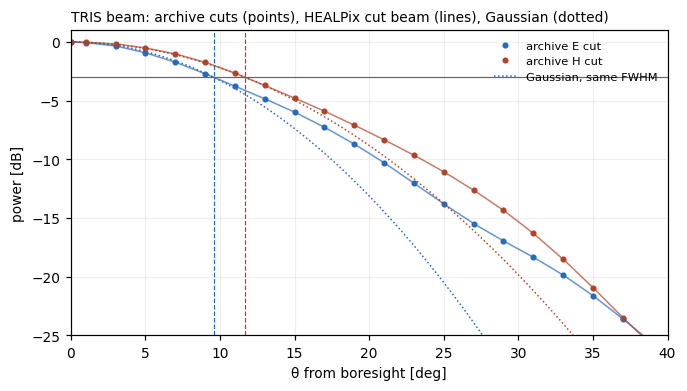

In [ ]:
ref_e, ref_h = CUTS.half_power_full_width_deg()
rows = [("half_power_full_width_deg()", ref_e, ref_h)]
for blend in ("db", "power"):
    resp = lambda phi: tris.tris_cut_beam_response(CUTS, theta, np.full(theta.size, phi), blend=blend)
    rows.append((f"tris_cut_beam_response, {blend} blend", fwhm_from_profile(theta, resp(0.0)),
                 fwhm_from_profile(theta, resp(90.0))))
cmap = tris.tris_cut_beam_map(CUTS, nside=NSIDE_T, normalization="peak")
rows.append(("tris_cut_beam_map, nside 512", fwhm_from_profile(theta, map_profile(cmap, 0)),
             fwhm_from_profile(theta, map_profile(cmap, 90))))

print(f"{'method':<40}{'E [deg]':>10}{'H [deg]':>10}")
for name, e, h in rows:
    print(f"{name:<40}{e:>10.4f}{h:>10.4f}")
for name, e, h in rows[1:]:
    record(f"{name}: E", round(e, 3), round(ref_e, 3), abs(e - ref_e) < 0.05)
    record(f"{name}: H", round(h, 3), round(ref_h, 3), abs(h - ref_h) < 0.05)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(CUTS.angle_deg, CUTS.e_plane_db, "o", ms=3, color="#256abf", label="archive E cut")
ax.plot(CUTS.angle_deg, CUTS.h_plane_db, "o", ms=3, color="#b2432a", label="archive H cut")
for phi, c in ((0, "#256abf"), (90, "#b2432a")):
    ax.plot(theta, 10 * np.log10(map_profile(cmap, phi)), "-", lw=1, color=c, alpha=0.7)
ax.plot(theta, 10 * np.log10(map_profile(gmap, 0)), ":", color="#256abf", lw=1, label="Gaussian, same FWHM")
ax.plot(theta, 10 * np.log10(map_profile(gmap, 90)), ":", color="#b2432a", lw=1)
ax.axhline(HALF_DB, color="0.4", lw=0.8)
for w, c in ((ref_e, "#256abf"), (ref_h, "#b2432a")):
    ax.axvline(w / 2, color=c, lw=0.8, ls="--")
ax.set_xlim(0, 40); ax.set_ylim(-25, 1)
ax.set_xlabel("θ from boresight [deg]"); ax.set_ylabel("power [dB]")
ax.set_title("TRIS beam: archive cuts (points), HEALPix cut beam (lines), Gaussian (dotted)",
             loc="left", fontsize=9)
ax.legend(fontsize=7.5, frameon=False); ax.grid(alpha=0.2)
plt.show()

---
## 5. φ = 0 is the E cut, φ = 90° is the H cut

The cut beam blends the cuts with weights $\cos^2\phi$ (E) and $\sin^2\phi$ (H), with φ in
**degrees** (converted inside with `np.deg2rad`). At the archive's own angles the response
must equal $10^{\mathrm{cut}/10}$ exactly at φ = 0° and 180° (E) and φ = 90° and 270° (H).

In floating point $\cos^2(90°) \approx 3.7\times10^{-33}$ rather than 0, so the comparison
is to relative precision $10^{-12}$, not bit-for-bit. A degree/radian slip in φ would show
up here: φ = π/2 passed in radians is read as 1.57°, which is essentially the E plane, not H.

In [ ]:
A = CUTS.angle_deg
E_lin, H_lin = 10 ** (CUTS.e_plane_db / 10), 10 ** (CUTS.h_plane_db / 10)
for blend in ("db", "power"):
    for phi, ref, plane in ((0.0, E_lin, "E"), (180.0, E_lin, "E"), (90.0, H_lin, "H"), (270.0, H_lin, "H")):
        got = tris.tris_cut_beam_response(CUTS, A, np.full(A.size, phi), blend=blend)
        err = np.max(np.abs(got / ref - 1))
        record(f"{blend} blend, phi={phi:.0f} -> {plane} cut (max rel. diff {err:.1e})",
               f"{err:.1e}", "< 1e-12", err < 1e-12)

# What a radian slip in phi would do: phi = pi/2 passed where degrees are expected.
slip = tris.tris_cut_beam_response(CUTS, A, np.full(A.size, np.pi / 2))
print(f"\nif phi were given in radians (pi/2 'degrees' = 1.57°): max deviation from the H cut "
      f"{np.max(np.abs(slip / H_lin - 1)):.2f}, from the E cut {np.max(np.abs(slip / E_lin - 1)):.4f}"
      f"  -> it returns the E cut, so the slip is detectable.")

# In between, the dB blend at 45° is the dB average of the two cuts.
mid = tris.tris_cut_beam_response(CUTS, A, np.full(A.size, 45.0), blend="db")
err = np.max(np.abs(10 * np.log10(mid) - 0.5 * (CUTS.e_plane_db + CUTS.h_plane_db)))
record("db blend at phi=45 is the dB mean of E and H", f"{err:.1e} dB", "< 1e-9", err < 1e-9)

PASS  db blend, phi=0 -> E cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)
PASS  db blend, phi=180 -> E cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)
PASS  db blend, phi=90 -> H cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)
PASS  db blend, phi=270 -> H cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)
PASS  power blend, phi=0 -> E cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)
PASS  power blend, phi=180 -> E cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)
PASS  power blend, phi=90 -> H cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)
PASS  power blend, phi=270 -> H cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)

if phi were given in radians (pi/2 'degrees' = 1.57°): max deviation from the H cut 4.58, from the E cut 0.0013  -> it returns the E cut, so the slip is detectable.
PASS  db blend at phi=45 is the dB mean of E and H: 7.1e-15 dB  (expected < 1e-9)


---
## 6. Test 2 — round trip on a beam with a known answer

**Procedure**

1. Build the elliptical Gaussian beam map with `approximate_tris_gaussian_beam_map`
   (FWHM_E = 19.155°, FWHM_H = 23.366°). This is a HEALPix map, the form limTOD uses.
2. Read the E and H cuts back off the map: sample it with `hp.get_interp_val` along
   φ = 0 and φ = 90°, and convert to dB as the archive stores them.
3. Wrap the cuts in a `TRISPrincipalPlaneCuts` and run the **same** FWHM function used on
   the archive, `half_power_full_width_deg()`.
4. Compare with 19.155° and 23.366°. **Pass: |error| ≤ 0.1%** (0.019° E, 0.023° H).

**Variations**, because each one isolates a different source of error:

* **nside 16 to 1024.** The map's pixelisation is what the round trip tests. The pipeline
  builds its beam at nside 16 (`tris.nside`, `tris.nside_hires`).
* **Two cut samplings:** fine (every 0.05°), and the archive's own angles (2° steps near
  half power). The archive grid isolates the linear-in-dB interpolation bias from §2.
* **Two normalisations:** `"none"` (the analytic function, peak = 1 at boresight exactly)
  and `"peak"` (divided by the brightest *pixel*, which is what the pipeline builds). At low
  nside no pixel sits on boresight, so the brightest pixel is below 1 and `"peak"` scales
  the whole beam up, which moves the −3 dB point outwards.

The 0.1% criterion is asserted for the configuration that tests the round trip itself:
fine sampling at nside ≥ 128. Every other row is reported, not asserted, and explained below
the table.

 nside  cut sampling  norm     E [deg]       ΔE   H [deg]       ΔH   0.1%?
    16  fine 0.05°    none     19.4265  +1.417%   23.1526  -0.913%   no
    16  fine 0.05°    peak     20.1736  +5.318%   24.0908  +3.102%   no
    16  archive       none     19.2951  +0.731%   23.1268  -1.024%   no
    16  archive       peak     20.0263  +4.549%   24.0388  +2.879%   no
    32  fine 0.05°    none     19.2207  +0.343%   23.3129  -0.227%   no
    32  fine 0.05°    peak     19.4054  +1.307%   23.5410  +0.749%   no
    32  archive       none     19.1345  -0.107%   23.2484  -0.503%   no
    32  archive       peak     19.3148  +0.834%   23.4701  +0.446%   no
    64  fine 0.05°    none     19.1683  +0.070%   23.3529  -0.056%   yes
    64  fine 0.05°    peak     19.2155  +0.316%   23.4094  +0.186%   no
    64  archive       none     19.0860  -0.360%   23.2797  -0.369%   no
    64  archive       peak     19.1307  -0.127%   23.3352  -0.132%   no
   128  fine 0.05°    none     19.1586  +0.019%   23.3628  -

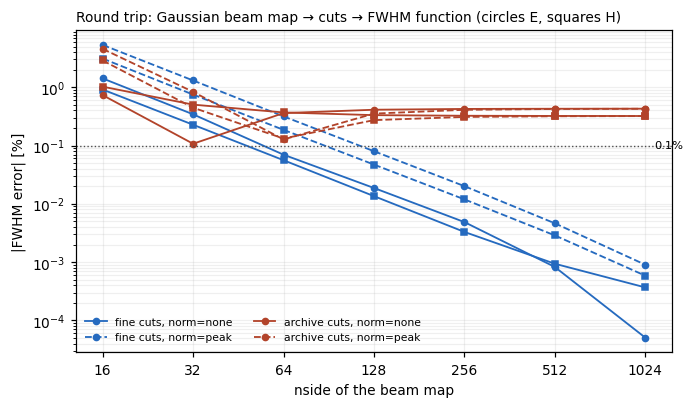

In [ ]:
TOL = 1e-3                                  # 0.1%
FINE = np.arange(0.0, 60.0, 0.05)

def round_trip(nside, angles, normalization):
    m = tris.approximate_tris_gaussian_beam_map(nside=nside, fwhm_e_deg=FWHM_E, fwhm_h_deg=FWHM_H,
                                                normalization=normalization)
    th = np.radians(angles)
    e = hp.get_interp_val(m, th, np.zeros_like(th))
    h = hp.get_interp_val(m, th, np.full_like(th, np.pi / 2))
    cuts = tris.TRISPrincipalPlaneCuts(angle_deg=angles, e_plane_db=10 * np.log10(e),
                                       h_plane_db=10 * np.log10(h))
    return cuts.half_power_full_width_deg()

RT = []
for nside in (16, 32, 64, 128, 256, 512, 1024):
    for grid, angles in (("fine 0.05°", FINE), ("archive", CUTS.angle_deg)):
        for norm in ("none", "peak"):
            e, h = round_trip(nside, angles, norm)
            RT.append(dict(nside=nside, grid=grid, norm=norm, e=e, h=h,
                           de=e / FWHM_E - 1, dh=h / FWHM_H - 1))

print(f"{'nside':>6}  {'cut sampling':<14}{'norm':<6}{'E [deg]':>10}{'ΔE':>9}{'H [deg]':>10}{'ΔH':>9}   0.1%?")
for r in RT:
    ok = abs(r["de"]) <= TOL and abs(r["dh"]) <= TOL
    print(f"{r['nside']:>6}  {r['grid']:<14}{r['norm']:<6}{r['e']:>10.4f}{100 * r['de']:>+8.3f}%"
          f"{r['h']:>10.4f}{100 * r['dh']:>+8.3f}%   {'yes' if ok else 'no'}")
print()
for r in RT:
    if r["grid"].startswith("fine") and r["nside"] >= 128:
        for plane, d, v, ref in (("E", r["de"], r["e"], FWHM_E), ("H", r["dh"], r["h"], FWHM_H)):
            record(f"round trip {plane}, nside {r['nside']}, norm {r['norm']} ({100 * d:+.3f}%)",
                   round(v, 4), ref, abs(d) <= TOL)

# The figure: |error| against nside, one line per configuration.
fig, ax = plt.subplots(figsize=(7, 3.8))
styles = {("fine 0.05°", "none"): ("#256abf", "-"), ("fine 0.05°", "peak"): ("#256abf", "--"),
          ("archive", "none"): ("#b2432a", "-"), ("archive", "peak"): ("#b2432a", "--")}
ns_list = sorted({r["nside"] for r in RT})
for (grid, norm), (c, ls) in styles.items():
    for plane, key, mk in (("E", "de", "o"), ("H", "dh", "s")):
        y = [100 * abs(next(r[key] for r in RT if r["nside"] == n and r["grid"] == grid and r["norm"] == norm))
             for n in ns_list]
        ax.plot(ns_list, y, ls, marker=mk, ms=4, color=c, lw=1.2,
                label=f"{grid.split()[0]} cuts, norm={norm}" if plane == "E" else None)
ax.axhline(100 * TOL, color="0.3", lw=0.9, ls=":")
ax.text(1100, 100 * TOL, "0.1%", va="center", fontsize=7.5)
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xticks(ns_list); ax.set_xticklabels(ns_list)
ax.set_xlabel("nside of the beam map"); ax.set_ylabel("|FWHM error| [%]")
ax.set_title("Round trip: Gaussian beam map → cuts → FWHM function (circles E, squares H)",
             loc="left", fontsize=9)
ax.legend(fontsize=7, frameon=False, ncol=2, loc="lower left"); ax.grid(alpha=0.2, which="both")
plt.show()

**Reading the table**

* **Pass, nside ≥ 128 with fine cut sampling:** both widths come back within 0.1%,
  converging to 0.001% at nside 1024. The FWHM function and the beam builder are
  consistent with each other.
* **Archive-grid rows, about −0.3% to −0.4% at every nside:** that is the linear-in-dB
  interpolation bias found in §2 (−0.08° E, −0.075° H). It does not shrink with nside,
  because it comes from the 2° sampling of the cuts, not from the map. The same bias is in
  the archive's own 19.155° and 23.366°.
* **nside 32 and 16 fail; nside 64 passes only with `norm = none`.** Two effects:
  * *Sampling:* a 3.7° pixel (nside 16) is a fifth of the E-plane FWHM, so reading the
    profile back by interpolating between pixel centres is only good to about 1%
    (`norm = none`: +1.4% E, −0.9% H).
  * *Peak normalisation:* at nside 16 the brightest pixel is 2.4° off boresight and holds
    about 0.95 of the true peak. Dividing by it scales the beam up by 5%, and the −3 dB
    point moves outwards: +5.3% (E) and +3.1% (H), about +1.0° and +0.7°.

**What this means for the pipeline.** The beam limTOD uses is built exactly this way, at
`tris.nside` = `tris.nside_hires` = 16, with `normalization="peak"`. limTOD then
normalises it by its sum (`normalize_beam=True`), which removes the peak scaling. So the
+5% is **not** a beam 5% too wide in the TODs. But the 3.7° sampling of a 19–23° beam
remains: the beam's shape, and how it falls between pixel centres, is only resolved to
about 1%. At nside 128 (0.46° pixels), the beam is reproduced to better than 0.1%.

---
## Summary

**No unit or σ-vs-FWHM error anywhere in the chain.** Every function returns the width it
is given, in degrees, with E on φ = 0 and H on φ = 90°. The σ ↔ FWHM constant is the exact
2√(2 ln 2), and the quadrature kernel and the smoothing combine as they should.

**Test 2 (round trip) passes at 0.1% for nside ≥ 128**, and fails below that (§6).

Three findings, all properties of the method rather than bugs:

1. **The 19.155° / 23.366° widths are from linear-in-dB interpolation on a 2° grid.** For a
   Gaussian that reads 0.08° narrow. Parabolic interpolation of the real cuts gives
   **19.19° (E) and 23.42° (H)**, +0.04° and +0.06°. The archive cannot settle which is
   right: it has no samples between 9° and 11° or between 11° and 13°. So the half-power
   widths carry about ±0.06° of interpolation uncertainty, 0.25% of the smoothing target.
2. **healpy's Gaussian smoothing at 23.366° has a real-space FWHM of 23.425°** (+0.25%),
   because a Gaussian in ℓ is not exactly a Gaussian in angle on the sphere at this width.
   The quadrature algebra is exact in ℓ, so stage 2 is self-consistent. If the target is
   meant to be a *real-space* 23.366°, the harmonic FWHM to request is about 23.31°.

3. **A beam map at nside 16 (the pipeline's beam grid) reproduces the Gaussian only to
   about 1%**, and its peak normalisation is off by 5% (removed again by limTOD's sum
   normalisation). At nside 128 the round trip is good to 0.08%, and at 512 to 0.005%.

Findings 1 and 2 shift the smoothed maps' effective beam by about 0.06°. That is negligible next to the
fact that the true TRIS beam is not Gaussian at all (figure in §4: it is much wider in the
shoulders below −10 dB), which no Gaussian smoothing kernel can match.

In [ ]:
n_pass = sum(r[3] for r in RESULTS)
print(f"{n_pass}/{len(RESULTS)} checks passed\n")
for check, value, expected, ok in RESULTS:
    print(f"  {'PASS' if ok else 'FAIL'}  {check}")

48/48 checks passed

  PASS  FWHM/sigma constant
  PASS  Gaussian(E) at FWHM/2
  PASS  Gaussian(H) at FWHM/2
  PASS  Gaussian E FWHM, fine grid
  PASS  Gaussian H FWHM, fine grid
  PASS  Gaussian E FWHM, archive grid = chord crossing
  PASS  Gaussian H FWHM, archive grid = chord crossing
  PASS  archive E FWHM
  PASS  archive H FWHM
  PASS  config target = archive H
  PASS  parabola method recovers a Gaussian exactly
  PASS  Gaussian map E width (phi=0)
  PASS  Gaussian map H width (phi=90)
  PASS  sigma-for-FWHM slip is detectable
  PASS  smooth_to_target(point source) width
  PASS  quadrature chain 5° -> target
  PASS  extra_fwhm_deg quadrature
  PASS  tris_cut_beam_response, db blend: E
  PASS  tris_cut_beam_response, db blend: H
  PASS  tris_cut_beam_response, power blend: E
  PASS  tris_cut_beam_response, power blend: H
  PASS  tris_cut_beam_map, nside 512: E
  PASS  tris_cut_beam_map, nside 512: H
  PASS  db blend, phi=0 -> E cut (max rel. diff 0.0e+00)
  PASS  db blend, phi=180 